# Does Winning the Toss Win the Match? (IPL 2008-2024)

Every IPL match starts with a coin toss, and commentators often treat it as a
decisive moment. Captains almost always choose to field first, which suggests
teams believe chasing is an advantage. This notebook checks whether the data
agrees.

**Question:** Does winning the toss improve a team's chances of winning the
match, and does the answer change with the toss decision, the venue, or the season?

**Dataset:** IPL Complete Dataset from Kaggle - `matches.csv`, covering 1095 matches
across 17 seasons.\
https://www.kaggle.com/datasets/patrickb1912/ipl-complete-dataset-20082020/data?select=matches.csv

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## EDA (Exploratory Data Analysis)

In [2]:
m = pd.read_csv("data/matches.csv")
m.T

,0,1,2,3,4,5,6,7,8,9,...,1085,1086,1087,1088,1089,1090,1091,1092,1093,1094
id,335982,335983,335984,335985,335986,335987,335988,335989,335990,335991,...,1426300,1426302,1426303,1426305,1426306,1426307,1426309,1426310,1426311,1426312
season,2007/08,2007/08,2007/08,2007/08,2007/08,2007/08,2007/08,2007/08,2007/08,2007/08,...,2024,2024,2024,2024,2024,2024,2024,2024,2024,2024
city,Bangalore,Chandigarh,Delhi,Mumbai,Kolkata,Jaipur,Hyderabad,Chennai,Hyderabad,Chandigarh,...,Bengaluru,Delhi,Guwahati,Mumbai,Bengaluru,Hyderabad,Ahmedabad,Ahmedabad,Chennai,Chennai
date,2008-04-18,2008-04-19,2008-04-19,2008-04-20,2008-04-20,2008-04-21,2008-04-22,2008-04-23,2008-04-24,2008-04-25,...,2024-05-12,2024-05-14,2024-05-15,2024-05-17,2024-05-18,2024-05-19,2024-05-21,2024-05-22,2024-05-24,2024-05-26
match_type,League,League,League,League,League,League,League,League,League,League,...,League,League,League,League,League,League,Qualifier 1,Eliminator,Qualifier 2,Final
player_of_match,BB McCullum,MEK Hussey,MF Maharoof,MV Boucher,DJ Hussey,SR Watson,V Sehwag,ML Hayden,YK Pathan,KC Sangakkara,...,C Green,I Sharma,SM Curran,N Pooran,F du Plessis,Abhishek Sharma,MA Starc,R Ashwin,Shahbaz Ahmed,MA Starc
venue,M Chinnaswamy Stadium,"Punjab Cricket Association Stadium, Mohali",Feroz Shah Kotla,Wankhede Stadium,Eden Gardens,Sawai Mansingh Stadium,"Rajiv Gandhi International Stadium, Uppal","MA Chidambaram Stadium, Chepauk","Rajiv Gandhi International Stadium, Uppal","Punjab Cricket Association Stadium, Mohali",...,"M Chinnaswamy Stadium, Bengaluru","Arun Jaitley Stadium, Delhi","Barsapara Cricket Stadium, Guwahati","Wankhede Stadium, Mumbai","M Chinnaswamy Stadium, Bengaluru","Rajiv Gandhi International Stadium, Uppal, Hyd...","Narendra Modi Stadium, Ahmedabad","Narendra Modi Stadium, Ahmedabad","MA Chidambaram Stadium, Chepauk, Chennai","MA Chidambaram Stadium, Chepauk, Chennai"
team1,Royal Challengers Bangalore,Kings XI Punjab,Delhi Daredevils,Mumbai Indians,Kolkata Knight Riders,Rajasthan Royals,Deccan Chargers,Chennai Super Kings,Deccan Chargers,Kings XI Punjab,...,Royal Challengers Bengaluru,Delhi Capitals,Rajasthan Royals,Lucknow Super Giants,Royal Challengers Bengaluru,Punjab Kings,Sunrisers Hyderabad,Royal Challengers Bengaluru,Sunrisers Hyderabad,Sunrisers Hyderabad
team2,Kolkata Knight Riders,Chennai Super Kings,Rajasthan Royals,Royal Challengers Bangalore,Deccan Chargers,Kings XI Punjab,Delhi Daredevils,Mumbai Indians,Rajasthan Royals,Mumbai Indians,...,Delhi Capitals,Lucknow Super Giants,Punjab Kings,Mumbai Indians,Chennai Super Kings,Sunrisers Hyderabad,Kolkata Knight Riders,Rajasthan Royals,Rajasthan Royals,Kolkata Knight Riders
toss_winner,Royal Challengers Bangalore,Chennai Super Kings,Rajasthan Royals,Mumbai Indians,Deccan Chargers,Kings XI Punjab,Deccan Chargers,Mumbai Indians,Rajasthan Royals,Mumbai Indians,...,Delhi Capitals,Lucknow Super Giants,Rajasthan Royals,Mumbai Indians,Chennai Super Kings,Punjab Kings,Sunrisers Hyderabad,Rajasthan Royals,Rajasthan Royals,Sunrisers Hyderabad


In [3]:
m.shape, m.columns

((1095, 20),
 Index(['id', 'season', 'city', 'date', 'match_type', 'player_of_match',
        'venue', 'team1', 'team2', 'toss_winner', 'toss_decision', 'winner',
        'result', 'result_margin', 'target_runs', 'target_overs', 'super_over',
        'method', 'umpire1', 'umpire2'],
       dtype='str'))

In [4]:
m.info

<bound method DataFrame.info of            id   season        city        date   match_type  player_of_match  \
0      335982  2007/08   Bangalore  2008-04-18       League      BB McCullum   
1      335983  2007/08  Chandigarh  2008-04-19       League       MEK Hussey   
2      335984  2007/08       Delhi  2008-04-19       League      MF Maharoof   
3      335985  2007/08      Mumbai  2008-04-20       League       MV Boucher   
4      335986  2007/08     Kolkata  2008-04-20       League        DJ Hussey   
...       ...      ...         ...         ...          ...              ...   
1090  1426307     2024   Hyderabad  2024-05-19       League  Abhishek Sharma   
1091  1426309     2024   Ahmedabad  2024-05-21  Qualifier 1         MA Starc   
1092  1426310     2024   Ahmedabad  2024-05-22   Eliminator         R Ashwin   
1093  1426311     2024     Chennai  2024-05-24  Qualifier 2    Shahbaz Ahmed   
1094  1426312     2024     Chennai  2024-05-26        Final         MA Starc   

       

In [5]:
m.dtypes

id                   int64
season                 str
city                   str
date                   str
match_type             str
player_of_match        str
venue                  str
team1                  str
team2                  str
toss_winner            str
toss_decision          str
winner                 str
result                 str
result_margin      float64
target_runs        float64
target_overs       float64
super_over             str
method                 str
umpire1                str
umpire2                str
dtype: object

In [6]:
m.season.unique()

<StringArray>
['2007/08',    '2009', '2009/10',    '2011',    '2012',    '2013',    '2014',
    '2015',    '2016',    '2017',    '2018',    '2019', '2020/21',    '2021',
    '2022',    '2023',    '2024']
Length: 17, dtype: str

#### Let's check for duplicate matches if any:

In [7]:
m["id"].duplicated().sum()

np.int64(0)

#### No duplicates
#### Let's now see how many matches there were per season:

In [8]:
m.groupby("season")["id"].count()

season
2007/08    58
2009       57
2009/10    60
2011       73
2012       74
2013       76
2014       60
2015       59
2016       60
2017       59
2018       60
2019       60
2020/21    60
2021       60
2022       74
2023       74
2024       71
Name: id, dtype: int64

#### Toss decision counts:

In [9]:
m.toss_decision.value_counts()

toss_decision
field    704
bat      391
Name: count, dtype: int64

In [10]:
# What if it relates by season?
pd.crosstab(m["season"], m["toss_decision"])

toss_decision,bat,field
season,,
2007/08,26,32
2009,35,22
2009/10,39,21
2011,25,48
2012,37,37
2013,45,31
2014,19,41
2015,25,34
2016,11,49


In [11]:
m.isna().sum()

id                    0
season                0
city                 51
date                  0
match_type            0
player_of_match       5
venue                 0
team1                 0
team2                 0
toss_winner           0
toss_decision         0
winner                5
result                0
result_margin        19
target_runs           3
target_overs          3
super_over            0
method             1074
umpire1               0
umpire2               0
dtype: int64

In [12]:
# Removing the tied games
md = m.dropna(subset="winner")
md.winner.isna().sum()
# We must keep in mind that a few games ended tied, in superover. We can remove it based on results.

np.int64(0)

In [13]:
# Converting str date to datetime
md["date"] = pd.to_datetime(md["date"])
md.date.dtype

dtype('<M8[us]')

In [14]:
# Rebuilding season
md["season"] = md.date.dt.year
md

,id,season,city,date,match_type,player_of_match,venue,team1,team2,toss_winner,toss_decision,winner,result,result_margin,target_runs,target_overs,super_over,method,umpire1,umpire2
0,335982,2008,Bangalore,2008-04-18,League,BB McCullum,M Chinnaswamy Stadium,Royal Challengers Bangalore,Kolkata Knight Riders,Royal Challengers Bangalore,field,Kolkata Knight Riders,runs,140.0,223.0,20.0,N,NaN,Asad Rauf,RE Koertzen
1,335983,2008,Chandigarh,2008-04-19,League,MEK Hussey,"Punjab Cricket Association Stadium, Mohali",Kings XI Punjab,Chennai Super Kings,Chennai Super Kings,bat,Chennai Super Kings,runs,33.0,241.0,20.0,N,NaN,MR Benson,SL Shastri
2,335984,2008,Delhi,2008-04-19,League,MF Maharoof,Feroz Shah Kotla,Delhi Daredevils,Rajasthan Royals,Rajasthan Royals,bat,Delhi Daredevils,wickets,9.0,130.0,20.0,N,NaN,Aleem Dar,GA Pratapkumar
3,335985,2008,Mumbai,2008-04-20,League,MV Boucher,Wankhede Stadium,Mumbai Indians,Royal Challengers Bangalore,Mumbai Indians,bat,Royal Challengers Bangalore,wickets,5.0,166.0,20.0,N,NaN,SJ Davis,DJ Harper
4,335986,2008,Kolkata,2008-04-20,League,DJ Hussey,Eden Gardens,Kolkata Knight Riders,Deccan Chargers,Deccan Chargers,bat,Kolkata Knight Riders,wickets,5.0,111.0,20.0,N,NaN,BF Bowden,K Hariharan
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1090,1426307,2024,Hyderabad,2024-05-19,League,Abhishek Sharma,"Rajiv Gandhi International Stadium, Uppal, Hyd...",Punjab Kings,Sunrisers Hyderabad,Punjab Kings,bat,Sunrisers Hyderabad,wickets,4.0,215.0,20.0,N,NaN,Nitin Menon,VK Sharma
1091,1426309,2024,Ahmedabad,2024-05-21,Qualifier 1,MA Starc,"Narendra Modi Stadium, Ahmedabad",Sunrisers Hyderabad,Kolkata Knight Riders,Sunrisers Hyderabad,bat,Kolkata Knight Riders,wickets,8.0,160.0,20.0,N,NaN,AK Chaudhary,R Pandit
1092,1426310,2024,Ahmedabad,2024-05-22,Eliminator,R Ashwin,"Narendra Modi Stadium, Ahmedabad",Royal Challengers Bengaluru,Rajasthan Royals,Rajasthan Royals,field,Rajasthan Royals,wickets,4.0,173.0,20.0,N,NaN,KN Ananthapadmanabhan,MV Saidharshan Kumar
1093,1426311,2024,Chennai,2024-05-24,Qualifier 2,Shahbaz Ahmed,"MA Chidambaram Stadium, Chepauk, Chennai",Sunrisers Hyderabad,Rajasthan Royals,Rajasthan Royals,field,Sunrisers Hyderabad,runs,36.0,176.0,20.0,N,NaN,Nitin Menon,VK Sharma


In [15]:
# Changing the NaN in method to 0
md.method.unique()

<StringArray>
[nan, 'D/L']
Length: 2, dtype: str

In [16]:
md.method = md.method.fillna("0")
md.method.unique()

<StringArray>
['0', 'D/L']
Length: 2, dtype: str

In [17]:
# Checking city corresponding to venue
md[md["city"].isna()]["venue"].value_counts()

venue
Dubai International Cricket Stadium    33
Sharjah Cricket Stadium                18
Name: count, dtype: int64

In [18]:
ven_to_city = {
    "Dubai International Cricket Stadium": "Dubai",
    "Sharjah Cricket Stadium": "Sharjah",
}

md["city"] = md["city"].fillna(md["venue"].map(ven_to_city))

In [19]:
# Standardizing venue names
print(md["venue"].unique().count())
sorted(md["venue"].unique())

58


['Arun Jaitley Stadium',
 'Arun Jaitley Stadium, Delhi',
 'Barabati Stadium',
 'Barsapara Cricket Stadium, Guwahati',
 'Bharat Ratna Shri Atal Bihari Vajpayee Ekana Cricket Stadium, Lucknow',
 'Brabourne Stadium',
 'Brabourne Stadium, Mumbai',
 'Buffalo Park',
 'De Beers Diamond Oval',
 'Dr DY Patil Sports Academy',
 'Dr DY Patil Sports Academy, Mumbai',
 'Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket Stadium',
 'Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket Stadium, Visakhapatnam',
 'Dubai International Cricket Stadium',
 'Eden Gardens',
 'Eden Gardens, Kolkata',
 'Feroz Shah Kotla',
 'Green Park',
 'Himachal Pradesh Cricket Association Stadium',
 'Himachal Pradesh Cricket Association Stadium, Dharamsala',
 'Holkar Cricket Stadium',
 'JSCA International Stadium Complex',
 'Kingsmead',
 'M Chinnaswamy Stadium',
 'M Chinnaswamy Stadium, Bengaluru',
 'M.Chinnaswamy Stadium',
 'MA Chidambaram Stadium',
 'MA Chidambaram Stadium, Chepauk',
 'MA Chidambaram Stadium, Chepauk, Chennai',
 'Maharaja

In [20]:
ven_map = {
    # Bengaluru
    "M Chinnaswamy Stadium": "M. Chinnaswamy Stadium, Bengaluru",
    "M Chinnaswamy Stadium, Bengaluru": "M. Chinnaswamy Stadium, Bengaluru",
    "M.Chinnaswamy Stadium": "M. Chinnaswamy Stadium, Bengaluru",
    
    # Mumbai
    "Wankhede Stadium": "Wankhede Stadium, Mumbai",
    "Wankhede Stadium, Mumbai": "Wankhede Stadium, Mumbai",
    "Brabourne Stadium": "Brabourne Stadium, Mumbai",
    "Brabourne Stadium, Mumbai": "Brabourne Stadium, Mumbai",
    "Dr DY Patil Sports Academy": "Dr DY Patil Sports Academy, Mumbai",
    "Dr DY Patil Sports Academy, Mumbai": "Dr DY Patil Sports Academy, Mumbai",
    
    # Kolkata
    "Eden Gardens": "Eden Gardens, Kolkata",
    "Eden Gardens, Kolkata": "Eden Gardens, Kolkata",
    
    # Delhi
    "Feroz Shah Kotla": "Arun Jaitley Stadium, Delhi",
    "Arun Jaitley Stadium": "Arun Jaitley Stadium, Delhi",
    "Arun Jaitley Stadium, Delhi": "Arun Jaitley Stadium, Delhi",
    
    # Chennai
    "MA Chidambaram Stadium, Chepauk": "MA Chidambaram Stadium, Chennai",
    "MA Chidambaram Stadium": "MA Chidambaram Stadium, Chennai",
    "MA Chidambaram Stadium, Chepauk, Chennai": "MA Chidambaram Stadium, Chennai",
    
    # Hyderabad
    "Rajiv Gandhi International Stadium, Uppal": "Rajiv Gandhi International Stadium, Hyderabad",
    "Rajiv Gandhi International Stadium": "Rajiv Gandhi International Stadium, Hyderabad",
    "Rajiv Gandhi International Stadium, Uppal, Hyderabad": "Rajiv Gandhi International Stadium, Hyderabad",
    
    # Mohali / Mullanpur
    "Punjab Cricket Association Stadium, Mohali": "Punjab Cricket Association IS Bindra Stadium, Mohali",
    "Punjab Cricket Association IS Bindra Stadium, Mohali": "Punjab Cricket Association IS Bindra Stadium, Mohali",
    "Punjab Cricket Association IS Bindra Stadium": "Punjab Cricket Association IS Bindra Stadium, Mohali",
    "Punjab Cricket Association IS Bindra Stadium, Mohali, Chandigarh": "Punjab Cricket Association IS Bindra Stadium, Mohali",
    "Maharaja Yadavindra Singh International Cricket Stadium, Mullanpur": "Maharaja Yadavindra Singh International Cricket Stadium, Mullanpur",
    
    # Jaipur
    "Sawai Mansingh Stadium": "Sawai Mansingh Stadium, Jaipur",
    "Sawai Mansingh Stadium, Jaipur": "Sawai Mansingh Stadium, Jaipur",
    
    # Ahmedabad
    "Sardar Patel Stadium, Motera": "Narendra Modi Stadium, Ahmedabad",
    "Narendra Modi Stadium, Ahmedabad": "Narendra Modi Stadium, Ahmedabad",
    
    # Pune
    "Maharashtra Cricket Association Stadium": "Maharashtra Cricket Association Stadium, Pune",
    "Maharashtra Cricket Association Stadium, Pune": "Maharashtra Cricket Association Stadium, Pune",
    "Subrata Roy Sahara Stadium": "Maharashtra Cricket Association Stadium, Pune",
    
    # Dharamsala
    "Himachal Pradesh Cricket Association Stadium": "Himachal Pradesh Cricket Association Stadium, Dharamsala",
    "Himachal Pradesh Cricket Association Stadium, Dharamsala": "Himachal Pradesh Cricket Association Stadium, Dharamsala",
    
    # Visakhapatnam
    "Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket Stadium": "Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket Stadium, Visakhapatnam",
    "Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket Stadium, Visakhapatnam": "Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket Stadium, Visakhapatnam",
    
    # Lucknow
    "Bharat Ratna Shri Atal Bihari Vajpayee Ekana Cricket Stadium, Lucknow": "Ekana Cricket Stadium, Lucknow",
    
    # Guwahati
    "Barsapara Cricket Stadium, Guwahati": "Barsapara Cricket Stadium, Guwahati",
    
    # UAE
    "Zayed Cricket Stadium, Abu Dhabi": "Sheikh Zayed Cricket Stadium, Abu Dhabi",
    "Sheikh Zayed Stadium": "Sheikh Zayed Cricket Stadium, Abu Dhabi",
}

md["venue"] = md["venue"].replace(ven_map)

In [21]:
md["venue"].unique().count()

np.int64(36)

In [22]:
# Standardizing team names
team_map = {
    # Active Franchises (including former names)
    "Chennai Super Kings": "CSK",
    "Delhi Daredevils": "DC",
    "Delhi Capitals": "DC",
    "Gujarat Titans": "GT",
    "Kolkata Knight Riders": "KKR",
    "Lucknow Super Giants": "LSG",
    "Mumbai Indians": "MI",
    "Kings XI Punjab": "PBKS",
    "Punjab Kings": "PBKS",
    "Rajasthan Royals": "RR",
    "Royal Challengers Bangalore": "RCB",
    "Royal Challengers Bengaluru": "RCB",
    "Sunrisers Hyderabad": "SRH",

    # Defunct Franchises
    "Deccan Chargers": "DCH",  
    "Gujarat Lions": "GL",
    "Kochi Tuskers Kerala": "KTK",
    "Pune Warriors": "PWI",
    "Rising Pune Supergiant": "RPS",
    "Rising Pune Supergiants": "RPS",
}

In [23]:
team_cols = ["team1", "team2", "toss_winner", "winner"]
md[team_cols] = md[team_cols].replace(team_map)

In [24]:
md

,id,season,city,date,match_type,player_of_match,venue,team1,team2,toss_winner,toss_decision,winner,result,result_margin,target_runs,target_overs,super_over,method,umpire1,umpire2
0,335982,2008,Bangalore,2008-04-18,League,BB McCullum,"M. Chinnaswamy Stadium, Bengaluru",RCB,KKR,RCB,field,KKR,runs,140.0,223.0,20.0,N,0,Asad Rauf,RE Koertzen
1,335983,2008,Chandigarh,2008-04-19,League,MEK Hussey,"Punjab Cricket Association IS Bindra Stadium, ...",PBKS,CSK,CSK,bat,CSK,runs,33.0,241.0,20.0,N,0,MR Benson,SL Shastri
2,335984,2008,Delhi,2008-04-19,League,MF Maharoof,"Arun Jaitley Stadium, Delhi",DC,RR,RR,bat,DC,wickets,9.0,130.0,20.0,N,0,Aleem Dar,GA Pratapkumar
3,335985,2008,Mumbai,2008-04-20,League,MV Boucher,"Wankhede Stadium, Mumbai",MI,RCB,MI,bat,RCB,wickets,5.0,166.0,20.0,N,0,SJ Davis,DJ Harper
4,335986,2008,Kolkata,2008-04-20,League,DJ Hussey,"Eden Gardens, Kolkata",KKR,DCH,DCH,bat,KKR,wickets,5.0,111.0,20.0,N,0,BF Bowden,K Hariharan
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1090,1426307,2024,Hyderabad,2024-05-19,League,Abhishek Sharma,"Rajiv Gandhi International Stadium, Hyderabad",PBKS,SRH,PBKS,bat,SRH,wickets,4.0,215.0,20.0,N,0,Nitin Menon,VK Sharma
1091,1426309,2024,Ahmedabad,2024-05-21,Qualifier 1,MA Starc,"Narendra Modi Stadium, Ahmedabad",SRH,KKR,SRH,bat,KKR,wickets,8.0,160.0,20.0,N,0,AK Chaudhary,R Pandit
1092,1426310,2024,Ahmedabad,2024-05-22,Eliminator,R Ashwin,"Narendra Modi Stadium, Ahmedabad",RCB,RR,RR,field,RR,wickets,4.0,173.0,20.0,N,0,KN Ananthapadmanabhan,MV Saidharshan Kumar
1093,1426311,2024,Chennai,2024-05-24,Qualifier 2,Shahbaz Ahmed,"MA Chidambaram Stadium, Chennai",SRH,RR,RR,field,SRH,runs,36.0,176.0,20.0,N,0,Nitin Menon,VK Sharma


In [25]:
# Checking whether the toss winner and game winner is always from the two teams
((md["toss_winner"] == md["team1"]) | (md["toss_winner"] == md["team2"])).value_counts()

True    1090
Name: count, dtype: int64

In [26]:
((md["winner"] == md["team1"]) | (md["winner"] == md["team2"])).value_counts()

True    1090
Name: count, dtype: int64

In [27]:
# Toss decision recalculated
print(md["toss_decision"].value_counts())

toss_decision
field    700
bat      390
Name: count, dtype: int64


In [28]:
# League vs knockout
knockout = md["match_type"] != "League"
print(knockout.map({False: "League", True: "Knockout"}).value_counts())

match_type
League      1024
Knockout      66
Name: count, dtype: int64


In [29]:
# Matches per season
print(md["season"].value_counts().sort_index())

season
2008    58
2009    57
2010    60
2011    72
2012    74
2013    76
2014    60
2015    57
2016    60
2017    59
2018    60
2019    59
2020    60
2021    60
2022    74
2023    73
2024    71
Name: count, dtype: int64


In [30]:
md.shape

(1090, 20)

#### Since we have 1090 matches in total, chance band would be:

In [31]:
margin = 1.96 * np.sqrt(0.25/1090)
margin

np.float64(0.02968334410795375)

In [32]:
print(50-margin*100, "< x <", 50+margin*100)

47.03166558920462 < x < 52.96833441079538


#### Where x is the probability.

Let us assume that `45 < x < 55` is a stronger indicator.

## Baseline
Based on matches which i have watched, i think win % for toss winners may be around 60%.

In [33]:
# Making a column for toss winners being game winners, 1 is true, 0 is false.
md["target"] = (md["toss_winner"] == md["winner"]).astype(int)

In [34]:
# Confidence Interval
n = len(md)
p_hat = md["target"].mean()
se = np.sqrt(p_hat * (1 - p_hat) / n)
ci_low, ci_high = p_hat - 1.96 * se, p_hat + 1.96 * se

In [35]:
# Chance band
chn_low, chn_high = 0.50 - margin, 0.50 + margin

In [38]:
# Calculating same with no ties (no super overs)
md_nt = md[md["super_over"] == "N"]
n_nt = len(md_nt)
p_nt = md_nt["target"].mean()

In [40]:
print(f"Baseline (n={n}): {p_hat*100:.2f})")
print(f"Baseline without Super Overs (n={n_nt}): {p_nt*100:.2f}")
print(f"95% CI: {ci_low*100:.2f} to {ci_high*100:.2f}")
print(f"Chn Band (50% +/- margin): {chn_low*100:.2f} to {chn_high*100:.2f}")

Baseline (n=1090): 50.83)
Baseline without Super Overs (n=1076): 50.93
95% CI: 47.86 to 53.79
Chn Band (50% +/- margin): 47.03 to 52.97


### Plotting it:

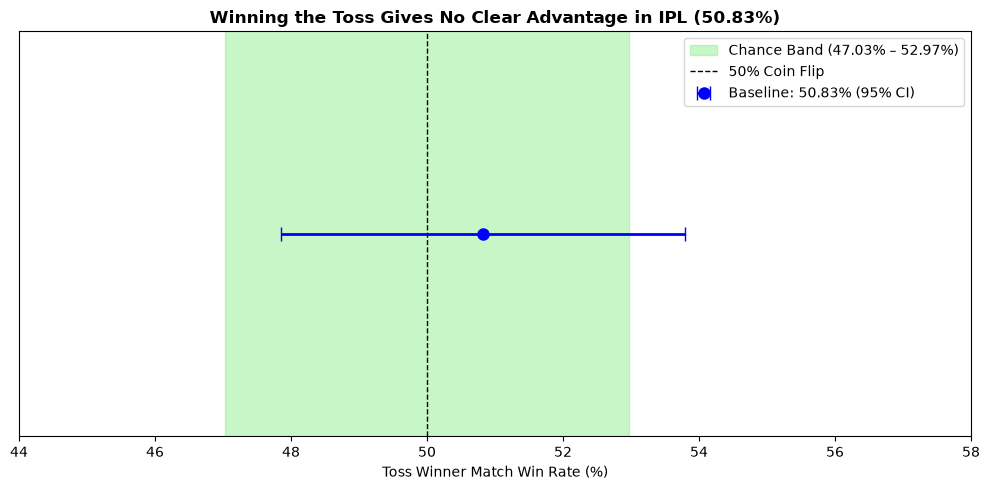

In [41]:
fig, ax = plt.subplots(figsize=(10, 5))

# Chance band
ax.axvspan(chn_low * 100, chn_high * 100, color="lightgreen", alpha=0.5, label="Chance Band (47.03% – 52.97%)")
ax.axvline(50, color="black", linestyle="--", linewidth=1, label="50% Coin Flip")

# Your observed baseline with 95% CI bar
ax.errorbar(
    x=p_hat * 100, y=0, xerr=1.96 * se * 100,
    fmt="o", color="blue", markersize=8, capsize=5, elinewidth=2,
    label=f"Baseline: {p_hat*100:.2f}% (95% CI)"
)

# Clean labels & minimal styling
ax.set_yticks([])
ax.set_xlim(44, 58)
ax.set_xlabel("Toss Winner Match Win Rate (%)")
ax.set_title("Winning the Toss Gives No Clear Advantage in IPL (50.83%)", fontweight="bold")
ax.legend()

plt.tight_layout()
plt.show()

#### Across 1,090 IPL matches from 2008 to 2024, winning the coin toss provides no statistically detectable overall advantage (50.83% win rate, well within the 47.03%–52.97% random chance band).

### Splitting data (into exploration and confirmation data sets)

In [74]:
exp_md = md[md["season"] <= 2018]
con_md = md[md["season"] >= 2019]

print(len(exp_md))
print(len(con_md))

693
397


In [75]:
def summarize(df, group_col):
    rows = []
    for val, grp in df.groupby(group_col):
        n = len(grp)
        rate = grp["target"].mean()
        se = np.sqrt(rate * (1 - rate) / n)
        ci_low, ci_high = rate - 1.96 * se, rate + 1.96 * se

        if n < 100:
            res = "Inconclusive, n < 100"
        elif 0.47 < rate < 0.53:
            res = "No detectable effect (47-53%)"
        elif 0.45 < rate < 0.55:
            res = "Detectable but small (53-55%)"
        else:
            res = "Meaningful (55%+)"
            
        rows.append({
            group_col: val,
            "n": n,
            "Win rate": f"{rate:.2%}",
            "95% CI": f"[{ci_low:.1%}, {ci_high:.1%}]",
            "Findings": res
        })
    return pd.DataFrame(rows)

# For exploration data (2008-2018)
summarize(exp_md, "toss_decision")

,toss_decision,n,Win rate,95% CI,Findings
0,bat,282,45.74%,"[39.9%, 51.6%]",Detectable but small (53-55%)
1,field,411,55.47%,"[50.7%, 60.3%]",Meaningful (55%+)


In [76]:
exp_md["stage"] = np.where(exp_md["match_type"] == "League", "League", "Knockout/Playoff")
print("=== EXPLORE (2008–2021): Match Stage ===")
display(summarize(exp_md, "stage"))

=== EXPLORE (2008–2021): Match Stage ===


,stage,n,Win rate,95% CI,Findings
0,Knockout/Playoff,42,59.52%,"[44.7%, 74.4%]","Inconclusive, n < 100"
1,League,651,51.00%,"[47.2%, 54.8%]",No detectable effect (47-53%)


In [77]:
# Checking the confirmation set (2019-2024)
summarize(con_md, "toss_decision")

,toss_decision,n,Win rate,95% CI,Findings
0,bat,108,44.44%,"[35.1%, 53.8%]",Meaningful (55%+)
1,field,289,51.56%,"[45.8%, 57.3%]",No detectable effect (47-53%)


## Conclusion

**Main Finding:**
Winning the toss does not give a real advantage in the IPL. Across 1,090 completed matches (2008–2024), the toss-winning team won **50.83%** of the time (95% CI: 47.86% to 53.79%), which falls inside our 47%–53% random chance band. Dropping the 14 super-over matches barely changed anything (50.93%).

**What Changed Across Splits:**
- **Toss Decision:** In the 2008–2018 exploration split, teams that chose to field first won **55.47%** (n = 411), which looked like a solid chasing advantage. However, on the 2019–2024 confirmation set, fielding first dropped to **51.56%** (n = 289)—right back in the random noise band. Batting first stayed below 50% in both splits (45.74% and 44.44%).
- **Match Stage:** League matches matched the baseline at **51.00%** (n = 651). Knockout/playoff matches had a **59.52%** rate in 2008–2018, but with only 42 matches, it stays inconclusive under the n >= 100 rule.

**What I Learned:**
- Setting the noise band (47%–53%) and minimum sample size (n >= 100) before slicing prevented me from over-interpreting small subgroups like playoffs. I had checked win rates based on studiums, and the data was skewed, hence I dropped it
- Splitting the data into explore (2008–2018) and confirm (2019–2024) sets saved the conclusion, otherwise, I would have reported the early chasing trend as a permanent rule.
- In data cleaning, I standardized 58 duplicate stadium names and team names, and rebuilt the season column from parsed dates.